# Trend and seasonality, read before modelling: what does a series tell you before any rule is chosen?

**Week 4, Friday, concept notebook 1 of 4, beside chapter 1 of the deck.** The chai stall is invented: it sits at a hostel gate, and every cup in this notebook is an invented number written by the day's seeded generator.

**Who needs the answer.** The stall's owner (invented), who orders milk every evening for
the next three days, and Flipkart's FC planner, who books packer shifts weeks ahead. A
reading that takes the weekly dip for a fall, or a weekday rise for growth, orders milk
that sours and packers who stand idle.

**The questions on the way.** What repeats, and how often? Is the stall growing? What
repeats once a year? What is left over?

In [1]:
import math
import pandas as pd
import matplotlib.pyplot as plt
plt.rcParams.update({"figure.figsize": (9, 3.8), "font.size": 11,
                     "axes.spines.top": False, "axes.spines.right": False})

def check(name, ok):
    print(("PASS " if ok else "FAIL ") + name)

# the invented stall's first fourteen days, and the same fourteen days 52 weeks later
two = pd.read_csv("../data/C2_W04_D05_chai_stall_fortnights_STUDENT.csv")
check("fourteen days in each year", len(two) == 14)
check("each 2025 day is the same weekday 364 days on",
      ((pd.to_datetime(two.date_2025) - pd.to_datetime(two.date_2024)).dt.days == 364).all())
two                                           # the whole table; every number in it is invented

PASS fourteen days in each year
PASS each 2025 day is the same weekday 364 days on


,day,weekday,date_2024,cups_2024,date_2025,cups_2025
0,1,Mon,2024-09-30,100,2025-09-29,112
1,2,Tue,2024-10-01,98,2025-09-30,111
2,3,Wed,2024-10-02,99,2025-10-01,108
3,4,Thu,2024-10-03,99,2025-10-02,118
4,5,Fri,2024-10-04,99,2025-10-03,104
5,6,Sat,2024-10-05,101,2025-10-04,109
6,7,Sun,2024-10-06,60,2025-10-05,66
7,8,Mon,2024-10-07,100,2025-10-06,110
8,9,Tue,2024-10-08,101,2025-10-07,108
9,10,Wed,2024-10-09,100,2025-10-08,105


## What repeats, and how often?

A **time series** is one number per equal period, in time order: cups a day at the stall
(invented), shipments a week at Flipkart, revenue a month at Kalpa. A **forecast** is a
number for a period nobody has seen yet.

**Predict before you run.** The stall (invented) sold 60 cups on Sunday 6 October 2024 and
100 on Monday 7 October. What does that say?

a) The stall is growing fast: Monday is 67 percent above the day before.
b) That is the weekly beat: Sundays always sell less, and nothing has grown.
c) Two days are too few to say anything.
d) Weekdays rose while Sundays did not.

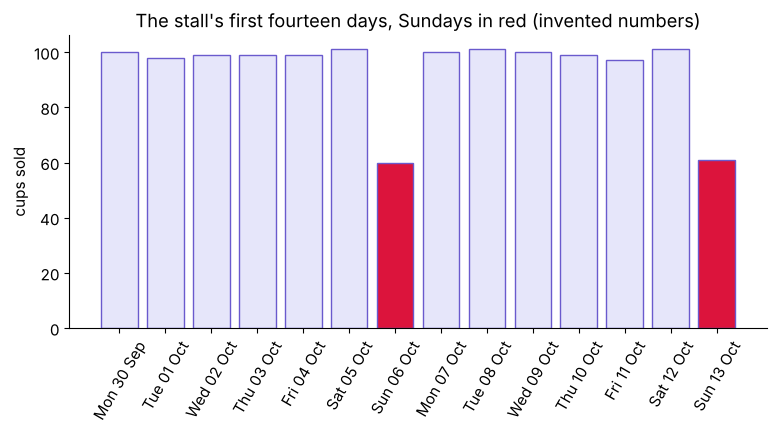

Monday over Sunday: 67% up
Monday against the Monday before: 100 against 100
PASS by hand and by code, Monday reads 67 percent above Sunday
PASS against the Monday before, the stall did not move


In [2]:
cups = two.set_index("date_2024").cups_2024                  # the 2024 fortnight, one number a day
labels = pd.to_datetime(two.date_2024).dt.strftime("%a %d %b")
fig, ax = plt.subplots()
ax.bar(labels, two.cups_2024, edgecolor="slateblue",
       color=["crimson" if d == "Sun" else "lavender" for d in two.weekday])
ax.tick_params(axis="x", rotation=60)
ax.set_ylabel("cups sold")
ax.set_title("The stall's first fourteen days, Sundays in red (invented numbers)")
plt.show()
by_hand = 100 / 60 - 1                                       # Monday over Sunday, counted by hand
by_code = cups["2024-10-07"] / cups["2024-10-06"] - 1
print(f"Monday over Sunday: {by_code:.0%} up")
print(f"Monday against the Monday before: {cups['2024-10-07']} against {cups['2024-09-30']}")
check("by hand and by code, Monday reads 67 percent above Sunday", round(by_hand, 4) == round(by_code, 4))
check("against the Monday before, the stall did not move", cups["2024-10-07"] == cups["2024-09-30"])

**What happened.** The answer is b. Both Sundays sold about 60 (60 and 61) and every other
day about 100. A repeat on a fixed beat is a **season**, and its **length** is the number of
periods before it repeats: 7 days here, 52 weeks in Flipkart's year. Monday against the
Monday before reads 100 against 100, so nothing grew this week.

## Is the stall growing?

Count it by hand first, comparing the same point a season apart. Monday 6 October 2025
sold 110 against Monday 7 October 2024's 100: 110 over 100 is 1.10, up 10 percent in a
year. Sunday 5 October 2025 sold 66 against 60: 1.10 again. The **trend** is that slow
climb, and the function below reads it for any pair of points.

Monday a season apart: 10%
the two fortnights: 1,450 over 1,315, 10.3%
Sunday's share of Monday: 0.6 in 2024 and 0.6 in 2025


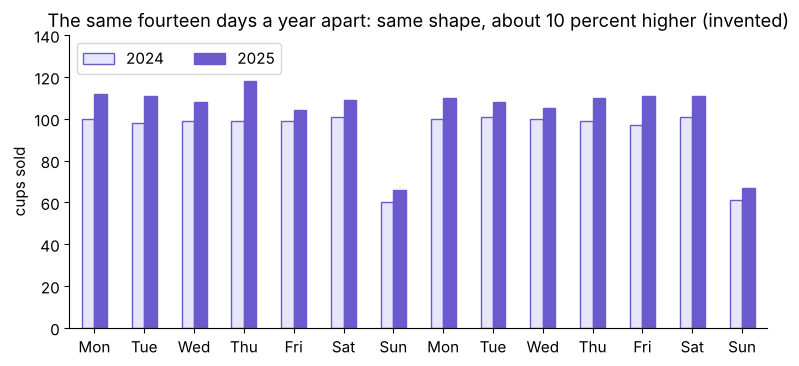

PASS by hand and by code, Monday grew 10 percent in a year
PASS Sunday's share stays 0.6 in both years


In [3]:
def season_apart(now, before):
    """Growth read the chapter's way: the same point one season apart, as a share."""
    return now / before - 1

monday = season_apart(two.cups_2025[7], two.cups_2024[7])            # Mon 6 Oct 2025 against Mon 7 Oct 2024
fortnight = season_apart(two.cups_2025.sum(), two.cups_2024.sum())    # all fourteen days at once
share = [two.cups_2024[6] / two.cups_2024[7], two.cups_2025[6] / two.cups_2025[7]]   # Sunday over Monday
print(f"Monday a season apart: {monday:.0%}")
print(f"the two fortnights: {two.cups_2025.sum():,} over {two.cups_2024.sum():,}, {fortnight:.1%}")
print(f"Sunday's share of Monday: {share[0]:.1f} in 2024 and {share[1]:.1f} in 2025")
ax = two[["cups_2024", "cups_2025"]].set_axis(["2024", "2025"], axis=1).plot.bar(color=["lavender", "slateblue"],
                                                                                 edgecolor="slateblue")
ax.set_xticklabels(two.weekday, rotation=0)
ax.set_ylim(0, 140)
ax.legend(ncol=2, loc="upper left")
ax.set_ylabel("cups sold")
ax.set_title("The same fourteen days a year apart: same shape, about 10 percent higher (invented)")
plt.show()
check("by hand and by code, Monday grew 10 percent in a year", round(monday, 2) == round(110 / 100 - 1, 2))
check("Sunday's share stays 0.6 in both years", [round(s, 1) for s in share] == [0.6, 0.6])

**What happened.** The stall (invented) grew 10 percent a year on the Mondays and 10.3
percent across the fortnight, while Sunday stayed 0.6 of a Monday in both years: the beat
keeps its shape as the level climbs.

## What repeats once a year?

The full record (invented) runs 730 days. Each semester closes with an exam fortnight, and
the hostel empties for Diwali week, the week that held Diwali on 31 October 2024 and on 20
October 2025.

**Predict before you run.** At the stall, is Diwali week a peak, like the exams, or a dip?

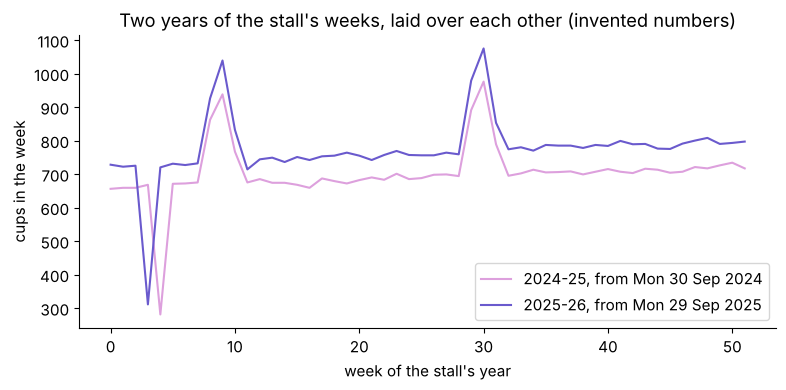

the exam fortnight over the fortnight before: 1.39 and 1.41
Diwali week over the fortnight before: 0.40 and 0.40
PASS the exam fortnight is about 1.4 times an ordinary fortnight, both years
PASS Diwali week is about 0.4 times an ordinary fortnight, both years


In [4]:
stall = pd.read_csv("../data/C2_W04_D05_chai_stall_daily_STUDENT.csv", parse_dates=["date"])
weekdays = stall[stall.weekday != "Sun"]

def season_ratio(start, days):
    """A season's weekdays against the fortnight of weekdays just before it."""
    start = pd.Timestamp(start)
    inside = weekdays[(weekdays.date >= start) & (weekdays.date < start + pd.Timedelta(days=days))]
    before = weekdays[(weekdays.date >= start - pd.Timedelta(days=14)) & (weekdays.date < start)]
    return inside.cups.mean() / before.cups.mean()

exam = [season_ratio("2024-11-27", 14), season_ratio("2025-11-26", 14)]     # the November exam fortnights
diwali = [season_ratio("2024-10-28", 7), season_ratio("2025-10-20", 7)]     # the weeks holding Diwali
stall["week"] = (stall.date - stall.date[0]).dt.days // 7                    # the stall's week, from Mon 30 Sep 2024
weekly = stall[stall.week < 104].groupby("week").cups.sum()
fig, ax = plt.subplots()
ax.plot(range(52), weekly.iloc[:52].values, color="plum", label="2024-25, from Mon 30 Sep 2024")
ax.plot(range(52), weekly.iloc[52:].values, color="slateblue", label="2025-26, from Mon 29 Sep 2025")
ax.set_xlabel("week of the stall's year")
ax.set_ylabel("cups in the week")
ax.set_title("Two years of the stall's weeks, laid over each other (invented numbers)")
ax.legend()
plt.show()
print(f"the exam fortnight over the fortnight before: {exam[0]:.2f} and {exam[1]:.2f}")
print(f"Diwali week over the fortnight before: {diwali[0]:.2f} and {diwali[1]:.2f}")
check("the exam fortnight is about 1.4 times an ordinary fortnight, both years", all(abs(r - 1.4) < 0.1 for r in exam))
check("Diwali week is about 0.4 times an ordinary fortnight, both years", all(abs(r - 0.4) < 0.1 for r in diwali))

**What happened.** Diwali week is a dip, about 0.4 of an ordinary week in both years (0.40
and 0.40), and the exam fortnight a peak, about 1.4 (1.39 and 1.41). A season repeats on a
fixed beat, up or down, so seasonal never means only a spike. Diwali's dip also lands a
week earlier in 2025, since the festival came eleven days earlier in the calendar, which
notebook 02 will need.

Named last: a series is a **trend** times its **seasons** times a **remainder**, what is
left over. Forecasting: Principles and Practice writes the parts as a sum, y = T + S + R,
when the seasons keep their size as the level grows, and as a product when they grow with
it, as the stall's do (section 3.2, checked 13 October 2026). A **cycle**, a rise and fall
with no fixed length, needs more than two years to see.

## What is left over?

Copy each day of the second year from the same weekday 364 days back, times 1.10 for the
year's growth; what the copy misses is the remainder. The fortnight Diwali moved into is
set aside, because there the copy lands the festival on the wrong days.

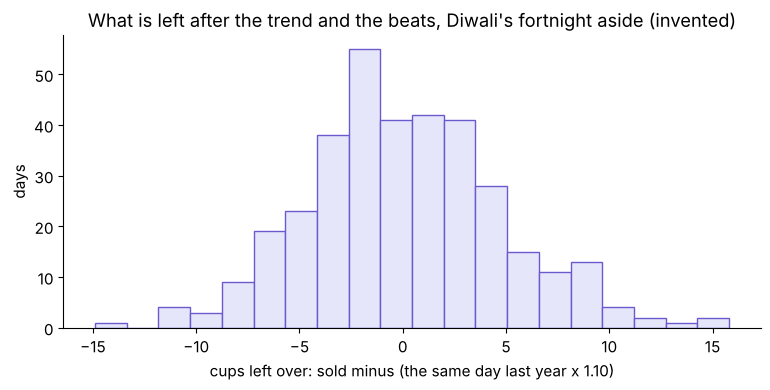

352 days: mean 0.1 cups, spread 4.7 cups either way
in the fortnight Diwali moved into, the worst day is 70 cups off
PASS what is left has a mean near zero
PASS what is left wobbles by a few cups


In [5]:
cups = stall.set_index("date").cups
year2 = cups[cups.index >= "2025-09-29"]                             # the second year
left = year2 - cups.shift(364).loc[year2.index] * 1.10               # what the trend and the beats leave
moved = (left.index >= "2025-10-20") & (left.index < "2025-11-03")   # the fortnight Diwali moved into
rest = left[~moved]
fig, ax = plt.subplots()
ax.hist(rest, bins=20, color="lavender", edgecolor="slateblue")
ax.set_xlabel("cups left over: sold minus (the same day last year x 1.10)")
ax.set_ylabel("days")
ax.set_title("What is left after the trend and the beats, Diwali's fortnight aside (invented)")
plt.show()
print(f"{len(rest)} days: mean {rest.mean():.1f} cups, spread {rest.std():.1f} cups either way")
print(f"in the fortnight Diwali moved into, the worst day is {left[moved].abs().max():.0f} cups off")
check("what is left has a mean near zero", abs(rest.mean()) < 1)
check("what is left wobbles by a few cups", rest.std() < 6)

**The plausible wrong answer.** "Monday sold 100 and Sunday 60, so the stall (invented) is
up 67 percent." **The decision it misleads:** two-thirds more milk ordered, which sours.
**The check:** the same point a season apart, Monday against the Monday before (100
against 100) or against the same Monday a year earlier (110 against 100). **The fix:** read
the beat first; the stall grows 10 percent a year, and this week it grew nothing.

The remainder shows the next trap. Inside the fortnight Diwali moved into, the copy of the
same weekday a year back misses by up to 70 cups, because the festival came eleven days
earlier in 2025. Notebook 02 copies by distance from the festival instead.

**Your turn.** Read the Sundays a season apart with `season_apart`. In the table at the top,
row 6 is Sunday 6 October 2024 and its 2025 twin sits in the same row. Fill the blanks, type
the lines into the empty cell below and run them; the check prints PASS when the reading is
right.

```python
sunday_then = two.cups_2024[6]          # Sunday 6 October 2024 (invented)
sunday_now = two.cups_2025[___]         # the same Sunday, 52 weeks later
growth = season_apart(___, ___)
check("Sundays grew about 10 percent a year", round(growth, 2) == 0.10)
```

## Which rules does the chapter leave?

1. Read the series' shape before choosing any rule that copies it.
2. A season repeats on a fixed beat, up or down, so count its length before using it.
3. Read growth by comparing the same point a season apart, never neighbours.
4. What is left after the trend and the seasons is the remainder, and a cycle needs years
   to see.

**In the interview.** "Before any model I plot the series and read its trend, its seasons
with their lengths, and what is left, because the baseline I must beat depends on them."

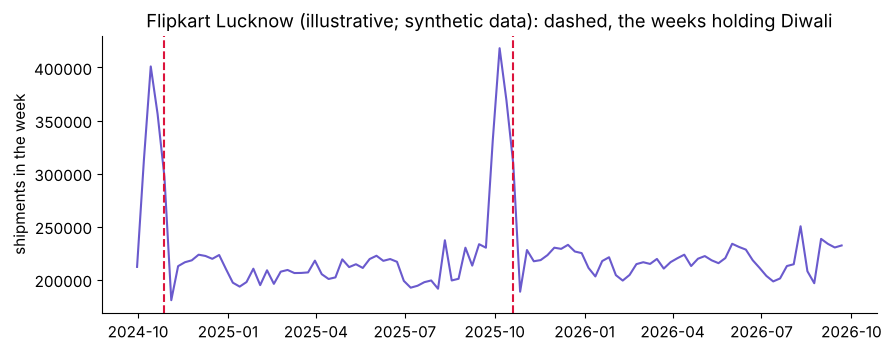

104 weeks; growth a season apart on the latest 39 training weeks: 4.0%
PASS Flipkart's weeks grow about 4 percent a year


In [6]:
weekly = pd.read_csv("../data/C2_W04_D05_weekly_shipments_STUDENT.csv", parse_dates=["week_start"])
y = weekly.set_index("week_start").shipments                   # Flipkart Lucknow, the case's 104 weeks
growth = season_apart(y.iloc[52:91].sum(), y.iloc[:39].sum())    # the latest 39 training weeks against a year earlier
fig, ax = plt.subplots(figsize=(10, 3.6))
ax.plot(y.index, y.values, color="slateblue")
for d in ["2024-10-28", "2025-10-20"]:
    ax.axvline(pd.Timestamp(d), color="crimson", ls="--")
ax.set_ylabel("shipments in the week")
ax.set_title("Flipkart Lucknow (illustrative; synthetic data): dashed, the weeks holding Diwali")
plt.show()
print(f"{len(y)} weeks; growth a season apart on the latest 39 training weeks: {growth:.1%}")
check("Flipkart's weeks grow about 4 percent a year", round(growth, 2) == 0.04)

## What did the chapter answer?

| Question | The stall's answer, in invented numbers |
|---|---|
| What repeats, and how often? | A Sunday dip every 7 days: Sunday sells 0.6 of a Monday |
| Is the stall growing? | By 10 percent a year, read a season apart; Monday's 67 percent over Sunday is the beat |
| What repeats once a year? | The exam fortnight, about 1.4 times an ordinary one, and Diwali week, about 0.4 |
| What is left over? | A wobble of 4.7 cups either way, except where the festival moved: up to 70 |

Flipkart's 104 weeks read the same way: a level near 210,000 shipments a week, growth of
about 4 percent a year and a festive peak each year. Chapter 5's notebook,
`C2_W04_D05_05_case_shape_and_baselines_STUDENT.ipynb`, applies this reading to them;
notebook 02 copies the stall's past three ways.